# Dataset Test – Audio-based Violence Detection Dataset (VSD)

Dataset: [Kaggle – fangfangz/audio-based-violence-detection-dataset](https://www.kaggle.com/datasets/fangfangz/audio-based-violence-detection-dataset)

**Expected folder layout** (next to this notebook):
```
dataset-testing/
├── dataset_testing.ipynb   ← this file
└── dataset/
    ├── audios_VSD/         ← audio files (any sub-folder is fine)
    └── VSD.xlsx            ← labels
```
**How the labels work:** VSD.xlsx does **not** give one label per file. For each *segment file* (e.g. `angry_011`) it lists the
time ranges (seconds) where violence happens. The `angry_01 … angry_21` files are the uncut original recordings those segments
were cut from, so they are skipped to avoid counting the same audio twice. The notebook cuts every segment file into short
windows and labels each window *violent* / *non-violent* from those time ranges.

**How to use:** run each cell from top to bottom with **Shift + Enter**. Read the output before moving on.

## Step 1 – Install and import libraries (first run takes 1–3 minutes)

In [1]:
%pip install -q pandas openpyxl numpy matplotlib librosa soundfile scikit-learn

import hashlib, json, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import soundfile as sf, librosa
from IPython.display import Audio, display
print("All libraries loaded ✅")

Note: you may need to restart the kernel to use updated packages.


All libraries loaded ✅


## Step 2 – Settings

In [2]:
AUDIO_DIR  = Path("dataset/audios_VSD")
LABEL_FILE = Path("dataset/VSD.xlsx")
RESULTS    = Path("results"); RESULTS.mkdir(exist_ok=True)

WINDOW_S = 3                          # length of each audio window in seconds
WINDOWS_PER_CLASS_FOR_MODEL = 300     # windows per class used in Step 9 (bigger = slower but more reliable)

print("Audio folder found:", AUDIO_DIR.exists())
print("Label file found:  ", LABEL_FILE.exists())

Audio folder found: True
Label file found:   True


## Step 3 – Look at the audio files

In [3]:
AUDIO_TYPES = {".wav", ".mp3", ".flac", ".ogg", ".m4a"}
audio_files = sorted(p for p in AUDIO_DIR.rglob("*") if p.suffix.lower() in AUDIO_TYPES)

print("Number of audio files:", len(audio_files))
print("File types:", pd.Series([p.suffix.lower() for p in audio_files]).value_counts().to_dict())
print("Sub-folders:", sorted({str(p.parent.relative_to(AUDIO_DIR)) for p in audio_files})[:10])
print("Example names:", [p.name for p in audio_files[:5]])

Number of audio files: 131
File types: {'.wav': 131}
Sub-folders: ['audios_VSD']
Example names: ['angry_01.wav', 'angry_011.wav', 'angry_012.wav', 'angry_013.wav', 'angry_014.wav']


## Step 4 – Look at the label file (VSD.xlsx)

In [4]:
sheets = pd.read_excel(LABEL_FILE, sheet_name=None)      # read every sheet
for name, sheet in sheets.items():
    print(f"Sheet '{name}': {sheet.shape[0]} rows, columns = {list(sheet.columns)}")
labels_raw = max(sheets.values(), key=len)                # use the biggest sheet
display(labels_raw.head(10))

Sheet 'Info': 341 rows, columns = ['Global_file_name', 'File_segment_name', 'Duration', 'Violence_start', 'Violence_end', 'Violence_duration']
Sheet 'read_dataset': 341 rows, columns = ['File_segment_name', 'Duration', 'Violence_start', 'Violence_end', 'Violence_duration']


,Global_file_name,File_segment_name,Duration,Violence_start,Violence_end,Violence_duration
0,angry_01,angry_011,117.0,21.0,38.000,17.00
1,NaN,NaN,NaN,40.0,55.000,15.00
2,NaN,NaN,NaN,60.0,79.000,19.00
3,NaN,NaN,NaN,85.0,95.000,10.00
4,NaN,NaN,NaN,101.0,110.000,9.00
5,NaN,angry_012,32.0,0.0,0.020,0.02
6,NaN,angry_013,72.0,0.0,0.010,0.00
7,NaN,angry_014,50.0,0.0,0.012,0.00
8,NaN,angry_015,162.0,64.0,71.000,7.00
9,NaN,NaN,NaN,89.0,100.000,11.00


## Step 5 – Match each audio file to its labels
The `read_dataset` sheet has one row per violent time range: `File_segment_name`, `Violence_start`, `Violence_end` (seconds).
Files with **no** violence are listed with a tiny placeholder range such as 0.00–0.01 s; any range shorter than
`MIN_VIOLENCE_S` is treated as "no violence in this file".

In [5]:
MIN_VIOLENCE_S = 0.25   # placeholder ranges in the Excel file are 0.001–0.2 s long; real ones are >= 0.65 s

def clean_name(v):
    if isinstance(v, float) and v.is_integer(): v = int(v)
    return Path(str(v).strip()).stem.lower()

def parent_of(stem):    # angry_011 -> angry_01, angry_049a -> angry_04, noviolence_01 -> noviolence_01
    m = re.match(r"(angry_\d\d)\d[a-z]?$", stem)
    return m.group(1) if m else stem

ann = sheets["read_dataset"].copy()
ann["stem"] = ann.File_segment_name.map(clean_name)
ann["real"] = (ann.Violence_end - ann.Violence_start) >= MIN_VIOLENCE_S
display(ann.head(8))

stems = {p.stem.lower(): p for p in audio_files}
segment_stems = set(ann.stem)
missing_audio = sorted(segment_stems - set(stems))
not_in_excel = sorted(set(stems) - segment_stems)
skipped_originals = [s for s in not_in_excel if re.fullmatch(r"angry_\d\d", s)]   # angry_01 ... angry_21
unlabelled = [s for s in not_in_excel if s not in skipped_originals]               # segment files with no labels
print("Segment files listed in Excel:   ", len(segment_stems))
print("Listed in Excel but no audio:    ", missing_audio)
print("Uncut original recordings (skipped):", len(skipped_originals), skipped_originals[:4], "...")
print("Segment audio with NO labels (skipped):", unlabelled)

,File_segment_name,Duration,Violence_start,Violence_end,Violence_duration,stem,real
0,angry_011,117.0,21.0,38.000,17.00,angry_011,True
1,angry_011,117.0,40.0,55.000,15.00,angry_011,True
2,angry_011,117.0,60.0,79.000,19.00,angry_011,True
3,angry_011,117.0,85.0,95.000,10.00,angry_011,True
4,angry_011,117.0,101.0,110.000,9.00,angry_011,True
5,angry_012,32.0,0.0,0.020,0.02,angry_012,False
6,angry_013,72.0,0.0,0.010,0.00,angry_013,False
7,angry_014,50.0,0.0,0.012,0.00,angry_014,False


Segment files listed in Excel:    109
Listed in Excel but no audio:     []
Uncut original recordings (skipped): 21 ['angry_01', 'angry_02', 'angry_03', 'angry_04'] ...
Segment audio with NO labels (skipped): ['angry_206']


In [6]:
intervals = (ann[ann.real].groupby("stem")[["Violence_start", "Violence_end"]]
             .apply(lambda d: list(zip(d.Violence_start, d.Violence_end))).to_dict())

data = ann.groupby("stem").Duration.first().rename("excel_seconds").reset_index()
data = data[data.stem.isin(stems)].reset_index(drop=True)
data["path"] = data.stem.map(lambda s: str(stems[s]))
data["source_recording"] = data.stem.map(parent_of)
data["violent_ranges"] = data.stem.map(lambda s: len(intervals.get(s, [])))
data["violent_seconds"] = data.stem.map(lambda s: sum(e - b for b, e in intervals.get(s, [])))
NAME = {0: "non-violent", 1: "violent"}

print("Matched segment files:          ", len(data))
print("  with violence:                ", (data.violent_ranges > 0).sum())
print("  without violence:             ", (data.violent_ranges == 0).sum())
print("Violent time ranges:            ", int(data.violent_ranges.sum()))
print("Original recordings they come from:", data.source_recording.nunique())

Matched segment files:           109
  with violence:                 85
  without violence:              24
Violent time ranges:             317
Original recordings they come from: 25


## Step 6 – Check every file: can it open? Length? Sample rate? Duplicates?

In [7]:
def check(path):
    info = {"readable": True, "seconds": np.nan, "sample_rate": np.nan, "channels": np.nan}
    try:
        i = sf.info(path)                                   # reads only the header -> fast
        info.update(seconds=i.duration, sample_rate=i.samplerate, channels=i.channels)
    except Exception:
        try:
            info.update(seconds=librosa.get_duration(path=path))
        except Exception:
            info["readable"] = False
    h = hashlib.sha256()                                     # fingerprint of the file
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    info["sha256"] = h.hexdigest()
    return info

print("Checking files... (a few minutes for the full dataset)")
data = pd.concat([data.reset_index(drop=True), pd.DataFrame([check(p) for p in data.path])], axis=1)

broken = data[~data.readable]
dup_groups = data[data.duplicated("sha256", keep=False)]
data["length_diff_s"] = (data.seconds - data.excel_seconds).abs()
length_mismatch = data[data.length_diff_s > 2]
past_end = [s for s, iv in intervals.items() if s in set(data.stem)
            and max(e for _, e in iv) > data.set_index("stem").seconds[s] + 1]
print("Unreadable files:                       ", len(broken))
print("Duplicate files:                        ", len(dup_groups))
print("Length differs from Excel by > 2 s:     ", len(length_mismatch), list(length_mismatch.stem)[:10])
print("Violence range goes past end of file:   ", len(past_end), past_end[:10])
data.to_csv(RESULTS / "file_check.csv", index=False)
print("Saved full list ->", RESULTS / "file_check.csv")

Checking files... (a few minutes for the full dataset)


Unreadable files:                        0
Duplicate files:                         0
Length differs from Excel by > 2 s:      1 ['angry_093']
Violence range goes past end of file:    0 []
Saved full list -> results/file_check.csv


## Step 7 – Cut into windows and simple statistics
Each file is cut into `WINDOW_S`-second windows. A window is **violent** if at least half of it is inside a violent range,
**non-violent** if none of it is, and skipped if it is only partly violent (unclear).

usable_files                       109
total_hours                        7.76
violent_hours                      0.85
violent_windows                    1027
non_violent_windows                8023
non_violent_from_noviolence_files  6035
balance_ratio                      7.81
violence_range_s                   {'shortest': 0.66, 'average': 9.62, 'longest': 141.26}
file_length_s                      {'shortest': 15.0, 'average': 256.2, 'longest': 4966.0}
sample_rates                       {'44100': 109}
channels                           {'2': 109}


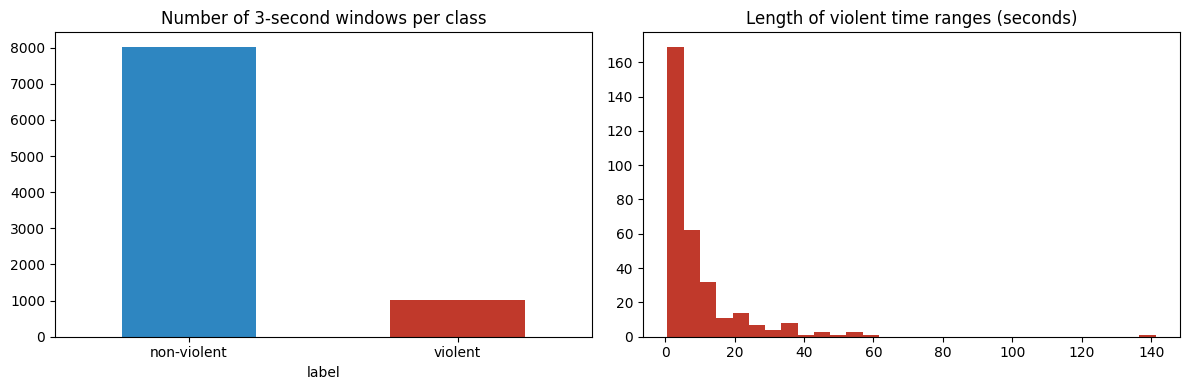

In [8]:
ok = data[data.readable].drop_duplicates("sha256").reset_index(drop=True)

rows = []
for r in ok.itertuples():
    iv = intervals.get(r.stem, [])
    for start in np.arange(0, r.seconds - WINDOW_S + 1e-9, WINDOW_S):
        end = start + WINDOW_S
        overlap = sum(max(0.0, min(end, e) - max(start, b)) for b, e in iv)
        if overlap >= WINDOW_S / 2: lab = 1
        elif overlap == 0:          lab = 0
        else:                       continue
        rows.append((r.stem, r.source_recording, r.path, round(start, 3), lab))
windows = pd.DataFrame(rows, columns=["stem", "source_recording", "path", "start", "label"])
windows.to_csv(RESULTS / "windows.csv", index=False)

counts = windows.label.map(NAME).value_counts()
ranges = pd.Series([e - b for iv in intervals.values() for b, e in iv])
nv_from_noviolence = ((windows.label == 0) & windows.stem.str.startswith("noviolence")).sum()
stats = {
    "usable_files": len(ok),
    "total_hours": round(float(ok.seconds.sum()) / 3600, 2),
    "violent_hours": round(float(ok.violent_seconds.sum()) / 3600, 2),
    "violent_windows": int(counts.get("violent", 0)),
    "non_violent_windows": int(counts.get("non-violent", 0)),
    "non_violent_from_noviolence_files": int(nv_from_noviolence),
    "balance_ratio": round(float(counts.max() / counts.min()), 2),
    "violence_range_s": {"shortest": round(float(ranges.min()), 2), "average": round(float(ranges.mean()), 2), "longest": round(float(ranges.max()), 2)},
    "file_length_s": {"shortest": round(float(ok.seconds.min()), 1), "average": round(float(ok.seconds.mean()), 1), "longest": round(float(ok.seconds.max()), 1)},
    "sample_rates": {str(int(k)): int(v) for k, v in ok.sample_rate.dropna().value_counts().items()},
    "channels": {str(int(k)): int(v) for k, v in ok.channels.dropna().value_counts().items()},
}
for k, v in stats.items(): print(f"{k:34} {v}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts.reindex(["non-violent", "violent"]).plot.bar(ax=ax[0], color=["#2e86c1", "#c0392b"], rot=0,
                                                    title=f"Number of {WINDOW_S}-second windows per class")
ax[1].hist(ranges, bins=30, color="#c0392b"); ax[1].set_title("Length of violent time ranges (seconds)")
plt.tight_layout(); plt.savefig(RESULTS / "stats.png", dpi=120); plt.show()

## Step 8 – Listen to examples (do the labels sound right?)

In [9]:
def load_window(path, start, seconds=WINDOW_S):
    y, sr = librosa.load(path, sr=16000, offset=float(start), duration=seconds)
    return y, sr

for lab in (1, 0):
    for w in windows[windows.label == lab].sample(2, random_state=1).itertuples():
        print(f"{NAME[lab].upper()} – {Path(w.path).name} at {w.start:.0f}s")
        y, sr = load_window(w.path, w.start)
        display(Audio(y, rate=sr))

VIOLENT – angry_143.wav at 48s


VIOLENT – angry_081.wav at 42s


NON-VIOLENT – noviolence_03.wav at 3276s


NON-VIOLENT – noviolence_04.wav at 1044s


## Step 9 – Quick learnability test
A simple model (not the final SafeGuard model) checks whether violent and non-violent windows can be told apart.
It uses `WINDOWS_PER_CLASS_FOR_MODEL` windows per class. Train and test windows come from **different original recordings**,
so the model cannot cheat by recognising the same recording.

Extracting features from 600 windows...


Train: 478 windows   Test: 122 windows   (test recordings: ['angry_13', 'angry_14', 'angry_17', 'angry_18', 'angry_19', 'angry_21', 'noviolence_02'])


              precision    recall  f1-score   support

 non-violent       0.63      0.88      0.74        57
     violent       0.84      0.55      0.67        65

    accuracy                           0.70       122
   macro avg       0.74      0.72      0.70       122
weighted avg       0.74      0.70      0.70       122



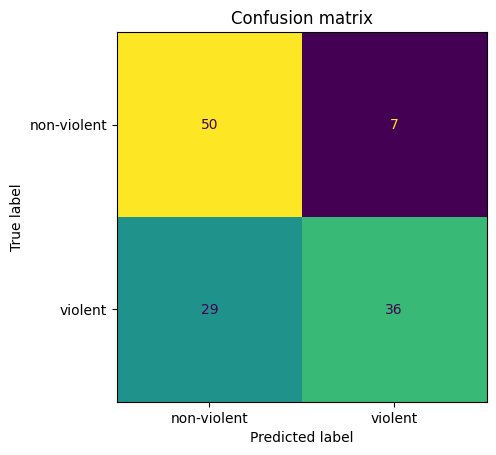

In [10]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, recall_score, precision_score

sample = pd.concat([windows[windows.label == lab].sample(min((windows.label == lab).sum(), WINDOWS_PER_CLASS_FOR_MODEL), random_state=42)
                    for lab in (0, 1)]).reset_index(drop=True)

def features(path, start, noise_db=None):
    y, sr = load_window(path, start)
    if noise_db is not None:                                   # add background noise at a chosen level
        noise = np.random.default_rng(0).standard_normal(len(y))
        y = y + noise * np.sqrt(np.mean(y**2) / (np.mean(noise**2) * 10 ** (noise_db / 10)))
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    return np.concatenate([mfcc.mean(1), mfcc.std(1), [np.sqrt(np.mean(y**2))]])

print(f"Extracting features from {len(sample)} windows...")
X = np.array([features(w.path, w.start) for w in sample.itertuples()]); y = sample.label.values
tr, te = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42).split(X, y, groups=sample.source_recording))
X_tr, X_te, y_tr, y_te = X[tr], X[te], y[tr], y[te]
test_windows = sample.iloc[te]
print(f"Train: {len(tr)} windows   Test: {len(te)} windows   "
      f"(test recordings: {sorted(test_windows.source_recording.unique())})")

model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42).fit(X_tr, y_tr)
pred = model.predict(X_te)

print(classification_report(y_te, pred, target_names=["non-violent", "violent"]))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["non-violent", "violent"], colorbar=False)
plt.title("Confusion matrix"); plt.savefig(RESULTS / "confusion_matrix.png", dpi=120); plt.show()

## Step 10 – Noise test (does it still work in a noisy home?)

,condition,violent_recall,false_alarm_rate
0,clean,0.554,0.123
1,noise 20 dB,0.862,0.070
2,noise 10 dB,0.692,0.018
3,noise 0 dB,0.108,0.000


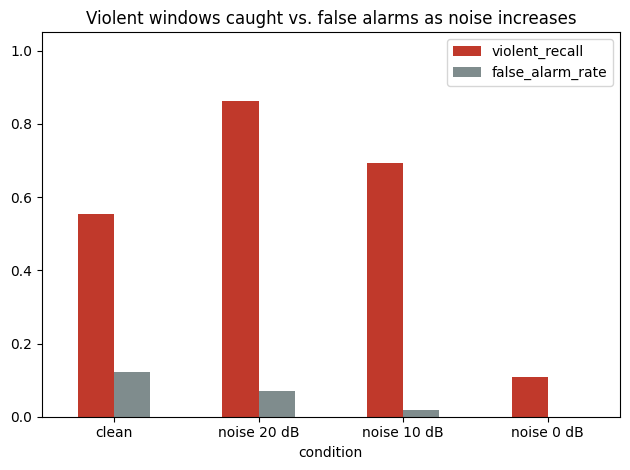

In [11]:
def scores(name, p):   # recall = violent windows caught; false_alarm = non-violent windows wrongly flagged
    return {"condition": name, "violent_recall": recall_score(y_te, p), "false_alarm_rate": float(np.mean(p[y_te == 0] == 1))}

noise_rows = [scores("clean", pred)]
for db in (20, 10, 0):
    Xn = np.array([features(w.path, w.start, noise_db=db) for w in test_windows.itertuples()])
    noise_rows.append(scores(f"noise {db} dB", model.predict(Xn)))
noise = pd.DataFrame(noise_rows).round(3); display(noise)
noise.to_csv(RESULTS / "noise_results.csv", index=False)
noise.plot.bar(x="condition", y=["violent_recall", "false_alarm_rate"], rot=0, ylim=(0, 1.05), color=["#c0392b", "#7f8c8d"],
               title="Violent windows caught vs. false alarms as noise increases")
plt.tight_layout(); plt.savefig(RESULTS / "noise_test.png", dpi=120); plt.show()

## Step 11 – Summary

In [12]:
recall, precision = recall_score(y_te, pred), precision_score(y_te, pred)
checks = {
    "All files open":                       len(broken) == 0,
    "No duplicate files":                   len(dup_groups) == 0,
    "Every labelled file has audio":        len(missing_audio) == 0,
    "Every segment audio file has labels":  len(unlabelled) == 0,
    "File lengths match the Excel file":    len(length_mismatch) == 0,
    "Classes balanced (ratio <= 3)":        stats["balance_ratio"] <= 3,
    "Model catches >= 85% violent windows": recall >= 0.85,
    "Still >= 70% with medium noise (10 dB)": noise.violent_recall.iloc[2] >= 0.70,
}
checks = {k: bool(v) for k, v in checks.items()}
for k, v in checks.items(): print("✅" if v else "❌", k)

summary = {**stats, "unreadable": len(broken), "duplicates": len(dup_groups),
           "missing_audio": missing_audio, "unlabelled_audio": unlabelled, "skipped_uncut_originals": len(skipped_originals),
           "length_mismatch_files": list(length_mismatch.stem),
           "violent_recall": round(recall, 3), "violent_precision": round(precision, 3),
           "noise_test": noise.to_dict("records"), "checks": checks}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("\nResults saved in the 'results' folder ✅")

✅ All files open
✅ No duplicate files
✅ Every labelled file has audio
❌ Every segment audio file has labels
❌ File lengths match the Excel file
❌ Classes balanced (ratio <= 3)
❌ Model catches >= 85% violent windows
❌ Still >= 70% with medium noise (10 dB)

Results saved in the 'results' folder ✅


## Conclusion
- **Size and balance:** 109 labelled segment files cut from 25 original recordings, 7.76 hours in total, all 44.1 kHz stereo WAV. Only 0.85 hours (about 11%) is violent, spread over 317 violent time ranges (0.66–141 s long, 9.6 s on average). Cut into 3-second windows this gives **1,027 violent vs 8,023 non-violent windows, a 7.8 : 1 imbalance** (fails the ≤ 3 target). 6,035 of the non-violent windows (75%) come from just four long `noviolence` recordings.
- **Problems found:** No unreadable or duplicate files. Two label issues: `angry_206.wav` has audio but **no labels** in VSD.xlsx (left out), and `angry_093.wav` is **78 s long but listed as 49 s**, so its violence times may be misaligned. The label file also needs care: it stores violence as time ranges (24 files use a 0.00–0.01 s placeholder for "no violence"), and the 21 uncut originals (`angry_01`–`angry_21`) repeat the same audio as the segments, so they must be left out to avoid double counting and train/test leakage.
- **Model result:** A simple baseline (Random Forest on MFCC features, 300 windows per class) tested on 122 windows from 7 recordings it never saw in training reached **violent recall 0.55, precision 0.84, accuracy 0.70**. The classes can be told apart better than chance, but the baseline misses almost half of the violent windows and fails the ≥ 85% recall target.
- **With noise:** Violent recall was 0.86 at 20 dB, **0.69 at 10 dB** (just under the 70% target) and 0.11 at 0 dB; false alarms were 12% clean, 7%, 2% and 0%. Detection collapses when the noise is as loud as the speech. Results are better at 20 dB than on clean audio, which shows the baseline is unstable on this small test set, so the noise numbers are only indicative.
- **Suitable for SafeGuard AI?** **Partly.** The audio is clean and readable, and the time-stamped labels are well suited to training a windowed detector. It is not ready to use as-is, though: (1) balance the classes (sampling or class weights), (2) split train/test by original recording, (3) fix or drop `angry_093` and `angry_206`, (4) add household-noise augmentation, and (5) since 75% of the non-violent audio comes from four recordings, a model may learn recording differences rather than violence, so combine VSD with other datasets and re-test with a stronger model (e.g. pretrained audio embeddings) before relying on it.
